# Naïve Bayes for Spam Email Detection
Spam email is unsolicited and electronic email sent with the aim of advertisement or phishing. Spam emails are on the rise these days, and requires a modern solution.

Naïve Bayes is one of the most widely used machine-learning approaches to the problem. It operates on the principle that the probability of an email being spam depends on the conditional probabilities of multiple word tokens appearing in the email. The probability that is highest (either being spam or ham) tends to be the outcome.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
nltk.download('stopwords')
nltk.download('all-corpora')

file_path = '/kaggle/input/datasets/karthickveerakumar/spam-filter/emails.csv'
df = pd.read_csv(file_path)

df.shape
print(df.head(10))
print(df.info())

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading collection 'all-corpora'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /usr/share/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to /usr/share/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package bcp47 to /usr/share/nltk_data...
[nltk_data]    | Downloading package biocreative_ppi to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package biocreative_ppi is already up-to-date!
[nltk_data]    | Downloading package brown to /usr/share/nltk_data...
[nltk_data]    |   Package brown is already up-to-date!
[nltk_data]    | Downloading package brown_tei to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package brown_tei is already up-to-date!
[nltk_data]    | Downloading package cess

                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1
5  Subject: great nnews  hello , welcome to medzo...     1
6  Subject: here ' s a hot play in motion  homela...     1
7  Subject: save your money buy getting this thin...     1
8  Subject: undeliverable : home based business f...     1
9  Subject: save your money buy getting this thin...     1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB
None


The dataset contains 2 columns and 5728 rows. No nulls reported, only data types include object and int64.

## Data Exploration
### Null & duplicate values

In [2]:
print(df.isnull().sum())
print('Duplicates:', df.duplicated().sum())

text    0
spam    0
dtype: int64
Duplicates: 33


There are no nulls in the dataset. However, 33 duplicates exist.

In [3]:
raw = df.copy()
df = raw.copy()

print(df.head())

                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1


Made a copy of the original dataset to preserve it.

In [4]:
df[df.duplicated(keep=False)].sort_values("text")

,text,spam
5716,Subject: * special notification * aurora versi...,0
3165,Subject: * special notification * aurora versi...,0
2473,"Subject: day off tuesday stinson , i would l...",0
1417,"Subject: day off tuesday stinson , i would l...",0
1801,Subject: departure of grant masson the resear...,0
...,...,...
3302,Subject: term project : this is the list of p...,0
3152,Subject: tiger evals - attachment tiger hosts...,0
2188,Subject: tiger evals - attachment tiger hosts...,0
4168,Subject: vp & director count for the research ...,0


The above output displays duplicate rows in the dataset. They do not provide any unique information to the dataset, and as such should be dropped.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)

### Target Class imbalance

spam
0    4327
1    1368
Name: count, dtype: int64


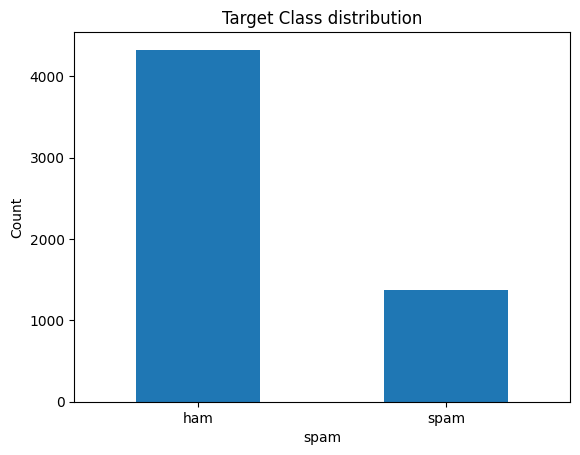

In [6]:
print(df['spam'].value_counts())
(df['spam'].value_counts(normalize=True))

df['spam'].value_counts().plot(kind='bar')
plt.xticks([0, 1], ['ham', 'spam'], rotation=0)
plt.ylabel('Count')
plt.title('Target Class distribution')
plt.show()

0 = ham, 1 = spam

Majority of the target constitutes ham (~ 76%). The classes are moderately imbalanced, so a model that always predicted "ham" would reach ~76% accuracy without detecting any spam. Accuracy alone is therefore misleading, and I'll evaluate with precision, recall, and F1 for the spam class.

### Exploration of target class

In [7]:
with pd.option_context("display.max_colwidth", None):
    print(df[df.spam == 0]["text"].sample(5))
    print(df[df.spam == 1]['text'].sample(5))

2699                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

**Ham (0):** Mostly internal business email: model reviews, hiring and interview logistics, data requests, short replies, and automated system messages (access approvals, mailing-list confirmations).

**Spam (1):** Promotional and scam content in several types: multi-level marketing, penny-stock promotion, advance-fee scams, pharmaceutical and pirated-software ads. Some messages include random filler text or raw email headers.

## Data Preprocessing
This step converts raw email text into a numeric matrix X and a label array y that scikit-learn can use.

In [8]:
df['text'] = df['text'].str.removeprefix('Subject:')
print(df['text'].sample())

2051     new frbny research : 5 / 3  please respond to...
Name: text, dtype: object



Removes the word 'Subject' at the start of every email

In [9]:
df['text'] = df['text'].map(lambda text: re.sub('[^a-zA-Z0-9]+', ' ', text)).apply(lambda x: (x.lower()).split())
with pd.option_context('display.max_colwidth', None):
    print(df['text'].sample())

5167    [december, 11, 2000, ews, prc, meeting, attached, is, an, agenda, and, attendee, list, for, the, december, 11, enron, wholesale, services, group, prc, meeting, the, first, part, of, this, meeting, will, involve, a, review, of, the, prc, results, below, vp, in, ena, eim, egm, and, enw, in, addition, to, a, discussion, and, approval, of, promotion, nominations, the, vp, preranking, will, begin, at, 9, 30, am, and, will, include, preranking, of, vp, s, in, ena, eim, egm, enw, calme, esa, and, apachi, please, note, on, the, attendee, list, which, part, of, the, meeting, you, need, to, attend, the, meeting, is, at, the, ...]
Name: text, dtype: object



re.sub replaces every character that is not a letter or a digit (punctuation, symbols) with a single space. 
The email is also converted into a list of words in lowercase.

In [10]:
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

def clean(text_list):
    kept = []
    for word in text_list:
        if word not in stop_words:
            kept.append(ps.stem(word))
    return ' '.join(kept)

corpus = df['text'].apply(clean)

Stop words are removed and the remaining words are stemmed.

- `PorterStemmer` reduces each word to its root, so word variants are counted as one feature instead of several.
- `stopwords.words('english')` is a list of common filler words that appear in almost every email, spam or ham, and so do not help distinguish between them. They are stored in a `set` for fast lookup.
- `clean()` loops through each email's word list, skips the stop words, stems the rest, and joins them back into a single string.
- `df['text'].apply(clean)` applies this to every email, producing `corpus`: one cleaned string per email.

Reduces noise and number of distinct features.

## Model Generation & Testing

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    corpus, df['spam'], test_size=0.2, random_state=42, stratify=df['spam']
)

cv = CountVectorizer(max_features=5000)
X_train = cv.fit_transform(X_train_text)
X_test = cv.transform(X_test_text)

print(X_train.shape, X_test.shape)

(4556, 5000) (1139, 5000)


The cleaned emails in `corpus` are text, and the model needs numbers, so two steps follow:

1. **Train/test split:** The data is split 80/20 into a training set (used to fit the model) and a test set (used only to evaluate it). The split is stratified, so the ham/spam ratio (~76/24) is the same in both sets. The split is done before vectorizing so that no information from the test emails leaks into training.

2. **Bag-of-words with `CountVectorizer`:** Each email is converted into a row of word counts.
   - `fit_transform` on the training set learns the vocabulary and builds the training matrix.
   - `transform` on the test set counts words using that same vocabulary. Words not in the vocabulary are ignored.
   - `max_features=5000` keeps only the 5000 most frequent words, which drops rare words (typos, names, one-off tokens) that add noise.

**Result:**

| Set | Shape | Meaning |
|-----|-------|---------|
| `X_train` | (4556, 5000) | 4556 emails, each described by counts of 5000 words |
| `X_test` | (1139, 5000) | 1139 emails, using the same 5000 words |

Both matrices have 5000 columns because they share one vocabulary. Most entries are 0, since any single email uses only a small fraction of the vocabulary. Word order is discarded and only counts remain, which is the form Naïve Bayes works with.

In [12]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()
classifier.fit(X_train, y_train)

MultinomialNB()

Confusion Matrix
[[851  14]
 [  2 272]]
The accuracy is: 98.60%

Classification Report
              precision    recall  f1-score   support

         ham       1.00      0.98      0.99       865
        spam       0.95      0.99      0.97       274

    accuracy                           0.99      1139
   macro avg       0.97      0.99      0.98      1139
weighted avg       0.99      0.99      0.99      1139



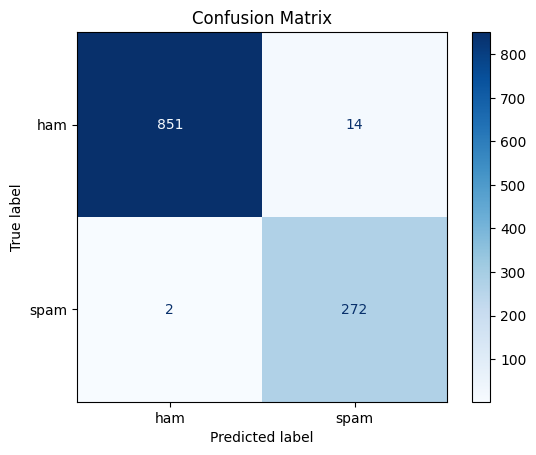

In [13]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict the test set
y_pred = classifier.predict(X_test)

# Confusion matrix and accuracy
matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix")
print(matrix)
print("The accuracy is: {:.2%}".format(accuracy_score(y_test, y_pred)))

# Precision, recall, F1 per class
print("\nClassification Report")
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

# Visual confusion matrix
ConfusionMatrixDisplay(matrix, display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

## Model Evaluation

The model was evaluated on the 1139 held-out test emails.

| | Predicted ham | Predicted spam |
|---|---|---|
| **Actual ham (865)** | 851 | 14 |
| **Actual spam (274)** | 2 | 272 |

**Accuracy: 98.60%**, well above the ~76% baseline of always predicting ham.

| Class | Precision | Recall | F1 |
|---|---|---|---|
| ham | 1.00 | 0.98 | 0.99 |
| spam | 0.95 | 0.99 | 0.97 |

- **Recall (spam) = 0.99:** only 2 of 274 spam emails reached the inbox.
- **Precision (spam) = 0.95:** 14 legitimate emails were wrongly flagged as spam.

The model leans towards over-flagging (14 false positives vs 2 false negatives). Since hiding a legitimate email is usually costlier than letting a spam email through, spam precision is the metric to improve. This could be done by raising the decision threshold using `predict_proba`, at some cost to recall.